In [92]:
import pandas as pd
import numpy as np

In [93]:
homework_2026_data_url= "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
# Load directly into memory
df = pd.read_csv(homework_2026_data_url)
list_variables_homework2 = ['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
df=df[list_variables_homework2]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


### Look at the fuel_efficiency_mpg variable. Does it have a long tail?

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

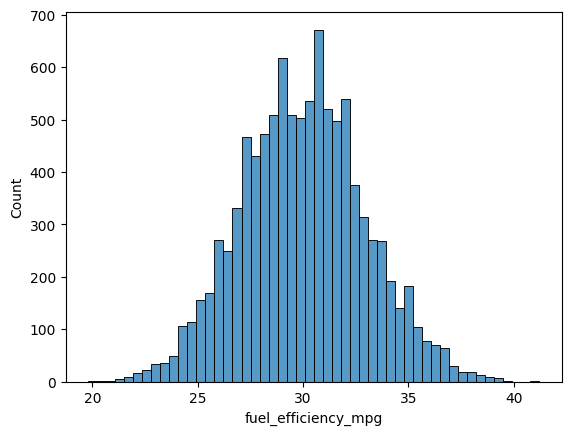

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.histplot(df.fuel_efficiency_mpg , bins=50)

# Question 1
There's one column with missing values. What is it?

'engine_displacement'

'horsepower'

'vehicle_weight'

'model_year'

In [95]:
df.isnull().sum()

,0
engine_displacement,0
horsepower,877
vehicle_weight,0
model_year,0
fuel_efficiency_mpg,0


# Question 2

What's the median (50% percentile) for variable 'horsepower'?

204

254

304

354

In [96]:
print("using the method median: ",df["horsepower"].median())
print("using describe: ", df['horsepower'].describe()['50%'])
print("using quantile: ",df['horsepower'].quantile(0.50))

using the method median:  254.0
using describe:  254.0
using quantile:  254.0


# Instructions for Q5 y Q6.
For Q5, repeat the same block with each listed seed. For Q6, use seed 9.

In [97]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

#Question 3

We need to deal with missing values for the column from Q1.

We have two options: fill it with 0 or with the mean of this variable.
Try both options. For each, train a linear regression model without regularization using the code from the lessons.

For computing the mean, use the training only!

Use the validation dataset to evaluate the models and compare the RMSE of each option.

Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.

Which option gives better RMSE?

Options:

With 0

With mean

Both are equally good

In [98]:
print("This is the length of the data sets.\n", "validation: ", n_val,"|", "test: ", n_test,"|", "training: ",n_train)

This is the length of the data sets.
 validation:  2000 | test:  2000 | training:  6000


In [99]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7
...,...,...,...,...,...
7895,2280,242.0,4590,2018,29.8
9590,2300,NaN,4240,1984,25.1
7288,2240,255.0,4190,1989,27.7
278,2430,254.0,4280,2020,31.6


In [100]:
#y_train = np.log1p(df_train.fuel_efficiency_mpg.values) # Si la variable fuera long tail
#y_val = np.log1p(df_val.fuel_efficiency_mpg.values) # Si la variable fuera long tail
#y_test = np.log1p(df_test.fuel_efficiency_mpg.values) # Si la variable fuera long tail

y_train = df_train.fuel_efficiency_mpg.values # Si la variable tiene una distribución normal
y_val = df_val.fuel_efficiency_mpg.values # Si la variable tiene una distribución normal
y_test = df_test.fuel_efficiency_mpg.values # Si la variable tiene una distribución normal

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

len(y_train)

6000

In [101]:
df_train.iloc[11]

,7487
engine_displacement,2460.0
horsepower,278.0
vehicle_weight,4410.0
model_year,1996.0


Defining the model :

<Axes: ylabel='Count'>

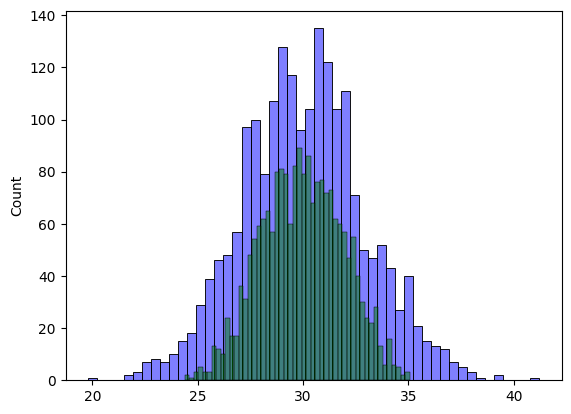

In [102]:
#entrenando el modelo sustituyendo los nan por 0 :
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

X_train = df_train.fillna(0).values
w0, w = train_linear_regression(X_train, y_train)

# validation :

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_val = prepare_X(df_val)
y_pred_0 = w0 + X_val.dot(w)
rmse_0=rmse(y_val, y_pred_0)

sns.histplot(y_val, color='blue', alpha=0.5, bins=50)
sns.histplot(y_pred_0, color='green', alpha=0.5, bins=50)

<Axes: ylabel='Count'>

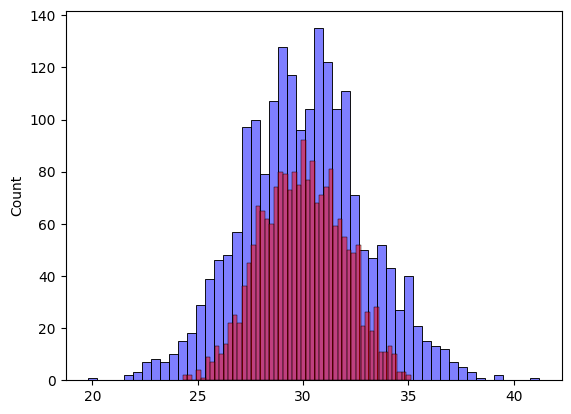

In [103]:
#entrenando el modelo sustituyendo los nan por el promedio :
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

X_train = df_train.fillna(df_train.mean()).values
w0, w = train_linear_regression(X_train, y_train)

# validation :

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(df.mean())
    X = df_num.values
    return X

X_val = prepare_X(df_val)
y_pred_mean = w0 + X_val.dot(w)
rmse_mean=rmse(y_val, y_pred_mean)

sns.histplot(y_val, color='blue', alpha=0.5, bins=50)
sns.histplot(y_pred_mean, color='red', alpha=0.5, bins=50)

In [104]:
print(f"Root mean square error nan values fill with 0: {rmse_0} \n",f"Root mean square error nan values fill with mean value: {rmse_mean}")
print("Un RMSE más bajo es indicadore de mejor desemepeño.")
print(f"la diferencia es {(rmse_0-rmse_mean)/rmse_0*100}%")

Root mean square error nan values fill with 0: 2.20529319475341 
 Root mean square error nan values fill with mean value: 2.2018099164429406
Un RMSE más bajo es indicadore de mejor desemepeño.
la diferencia es 0.15795080303863873%


The mean as fill value is better , it helps the dataset to keep the center distribution. Also, the eficiency of a car is almost imposible to be 0.


# Question 4

Now let's train a regularized linear regression.

For this question, fill the NAs with 0.

Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
Use RMSE to evaluate the model on the validation dataset.

Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.

Which r gives the best RMSE? If multiple options give the same best RMSE, select the smallest r.

Options:

0

0.01

0.1

1

5

10

100

In [126]:
def train_linear_regression_reg(X, y, r=0.01):
      ones = np.ones(X.shape[0])
      X = np.column_stack([ones, X])

      XTX = X.T.dot(X)
      XTX = XTX + r * np.eye(XTX.shape[0])

      XTX_inv = np.linalg.inv(XTX)
      w_full = XTX_inv.dot(X.T).dot(y)

      return w_full[0], w_full[1:]

def prepare_X_y(df):
        df_num = df.fillna(0)
        y = df_num.fuel_efficiency_mpg.values # se aplica para el y definido como fuel_efficiency_mpg
        del df_num['fuel_efficiency_mpg'] #se elimina del df para definir X.
        X = df_num
        return X,y

def rmse(y, y_pred):
      se = (y - y_pred) ** 2
      mse = se.mean()
      return np.sqrt(mse)

RMSE_q4={"r":[],"RMSE":[]}
for i in [0,0.01,0.1,1,5,10,100]:
  X_train,y_train = prepare_X_y(df_train)
  w0, w = train_linear_regression_reg(X_train, y_train, r=i)
  X_val,y_val = prepare_X_y(df_val)
  y_pred = w0 + X_val.dot(w)
  print(f"Hiper-parámetro  r: {i} ---> RMSE: {round(rmse(y_val, y_pred),4)}")

  RMSE_q4["r"].append(i)
  RMSE_q4["RMSE"].append(round(rmse(y_val, y_pred),4))
df_q4=pd.DataFrame(RMSE_q4)
df_q4.loc[df_q4['RMSE'].idxmin()]


Hiper-parámetro  r: 0 ---> RMSE: 2.207
Hiper-parámetro  r: 0.01 ---> RMSE: 2.2067
Hiper-parámetro  r: 0.1 ---> RMSE: 2.2195
Hiper-parámetro  r: 1 ---> RMSE: 2.3364
Hiper-parámetro  r: 5 ---> RMSE: 2.3952
Hiper-parámetro  r: 10 ---> RMSE: 2.4051
Hiper-parámetro  r: 100 ---> RMSE: 2.4146


,1
r,0.0100
RMSE,2.2067


# Question 5

We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.

Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].

For each seed, do the train/validation/test split with 60%/20%/20% distribution.
Fill the missing values with 0 and train a model without regularization.

For each seed, evaluate the model on the validation dataset and collect the RMSE scores.

What's the standard deviation of all the scores? To compute the standard deviation, use np.std.

Round the result to 3 decimal digits (round(std, 3))

What's the value of std?

0.006

0.016

0.029

0.036

Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. If it's high, the values are different. If standard deviation of scores is low, then our model is stable.

In [111]:
def train_linear_regression_reg(X, y, r=0):
      ones = np.ones(X.shape[0])
      X = np.column_stack([ones, X])

      XTX = X.T.dot(X)
      XTX = XTX + r * np.eye(XTX.shape[0])

      XTX_inv = np.linalg.inv(XTX)
      w_full = XTX_inv.dot(X.T).dot(y)

      return w_full[0], w_full[1:]

def prepare_X_y(df):
      df_num = df.fillna(0)
      y = df_num.fuel_efficiency_mpg.values # se aplica para el y definido como fuel_efficiency_mpg
      del df_num['fuel_efficiency_mpg'] #se elimina del df para definir X.
      X = df_num
      return X,y

def rmse(y, y_pred):
      se = (y - y_pred) ** 2
      mse = se.mean()
      return np.sqrt(mse)

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

RMSE_seeds = []
for s in [0,1,2,3,4,5,6,7,8,9]:
  np.random.seed(s) #probando diferentes valores de seed "s"
  idx = np.arange(n)
  np.random.shuffle(idx)

  # re organizar X y con el mismo índice mezclado
  df_train = df.iloc[idx[:n_train]]
  df_val = df.iloc[idx[n_train:n_train + n_val]]
  df_test = df.iloc[idx[n_train + n_val:]]

  # preparo X y a partir de mis datos.
  X_train,y_train = prepare_X_y(df_train)
  w0, w = train_linear_regression_reg(X_train, y_train, r=0) #r=0 es decir sin regularización.
  X_val,y_val = prepare_X_y(df_val)
  y_pred = w0 + X_val.dot(w)
  print(f"seed:  {s} --> RMSE: {round(rmse(y_val, y_pred),4)}")
  RMSE_seeds.append(round(rmse(y_val, y_pred),4))
round(np.std(RMSE_seeds),3)

seed:  0 --> RMSE: 2.2392
seed:  1 --> RMSE: 2.2021
seed:  2 --> RMSE: 2.1634
seed:  3 --> RMSE: 2.2044
seed:  4 --> RMSE: 2.2019
seed:  5 --> RMSE: 2.2458
seed:  6 --> RMSE: 2.2697
seed:  7 --> RMSE: 2.1908
seed:  8 --> RMSE: 2.2166
seed:  9 --> RMSE: 2.207


np.float64(0.029)

# Question 6

Split the dataset like previously, use seed 9.

Combine train and validation datasets.

Fill the missing values with 0 and train a model with r=0.001.

What's the RMSE on the test dataset?

Options:

0.236

2.236

22.10

221.0

In [131]:
def train_linear_regression_reg(X, y, r=0):
      ones = np.ones(X.shape[0])
      X = np.column_stack([ones, X])

      XTX = X.T.dot(X)
      XTX = XTX + r * np.eye(XTX.shape[0])

      XTX_inv = np.linalg.inv(XTX)
      w_full = XTX_inv.dot(X.T).dot(y)

      return w_full[0], w_full[1:]

def prepare_X_y(df):
      df_num = df.fillna(0)
      y = df_num.fuel_efficiency_mpg.values # se aplica para el y definido como fuel_efficiency_mpg
      del df_num['fuel_efficiency_mpg'] #se elimina del df para definir X.
      X = df_num
      return X,y

def rmse(y, y_pred):
      se = (y - y_pred) ** 2
      mse = se.mean()
      return np.sqrt(mse)

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

RMSE_seeds = []
for s in [9]:
  np.random.seed(s) #probando diferentes valores de seed "s"
  idx = np.arange(n)
  np.random.shuffle(idx)

  # re organizar X y con el mismo índice mezclado
  df_train = df.iloc[idx[:n_train]]
  df_val = df.iloc[idx[n_train:n_train + n_val]]
  df_test = df.iloc[idx[n_train + n_val:]]
  df_train_val=pd.concat([df_train, df_val], ignore_index=True)

  # preparo X y a partir de mis datos.
  X_train_val,y_train_val = prepare_X_y(df_train_val)
  w0, w = train_linear_regression_reg(X_train_val, y_train_val, r=0.01)
  X_test,y_test = prepare_X_y(df_test)
  y_pred = w0 + X_test.dot(w)
  print(f"seed:  {s} --> RMSE: {round(rmse(y_test, y_pred),3)}")
  RMSE_seeds.append(round(rmse(y_test, y_pred),3))

seed:  9 --> RMSE: 2.236
